<a href="https://colab.research.google.com/github/surei09/ONECARE-AI/blob/main/ONECARE_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

       [ONECARE AI] 일상 건강 및 복약 상태 입력
1. 성함을 입력하세요 (예: 박가을): 현수아
2. 현재 복용 중인 처방약 개수를 입력하세요 (예: 5): 3
3. 최근 일주일 복약 이행률(%)을 입력하세요 (0~100, 예: 75): 43
4. 가장 불편한 증상을 입력하세요 (예: 어지러움, 속쓰림): 발열
5. 증상 강도를 입력하세요 (1: 매우 약함 ~ 10: 매우 심함, 예: 7): 5
6. 증상이 며칠째 지속되고 있나요? (예: 4): 5
7. 일주일 동안 해당 증상이 몇 번 반복되었나요? (예: 5): 5
8. 하루 평균 수면 시간을 입력하세요 (예: 5.5): 8

       [ONECARE AI 진료 준비 자동 분석 보고서]
■ 환자 성함: 현수아 님
■ 주요 호소 증상: 발열 (강도 5/10, 5일 지속, 주 5회)
■ 가공된 핵심 건강 지표:
  - 다약제 위험 여부: 일반군 (5개 미만 복용)
  - 증상 심각도 복합점수: 5.0점 (기준치: 6.5점 이상 고위험)
  - 복약 순응도 평가: 관리 미흡 (80% 미만)
-------------------------------------------------------
▶ AI 종합 분류 결과: 【 복약 관리 필요형 】
▶ AI 권고 안내: 복약 이행률이 낮거나 증상이 반복되고 있습니다.
   알람 설정을 통해 정해진 시간에 복약하시고, 3일 이상 증상 지속 시 병원 상담을 권장합니다.



/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128204 (\N{PUSHPIN}) missing from font(s) NanumGothic.
  fig.canvas.print_figure(bytes_io, **kw)


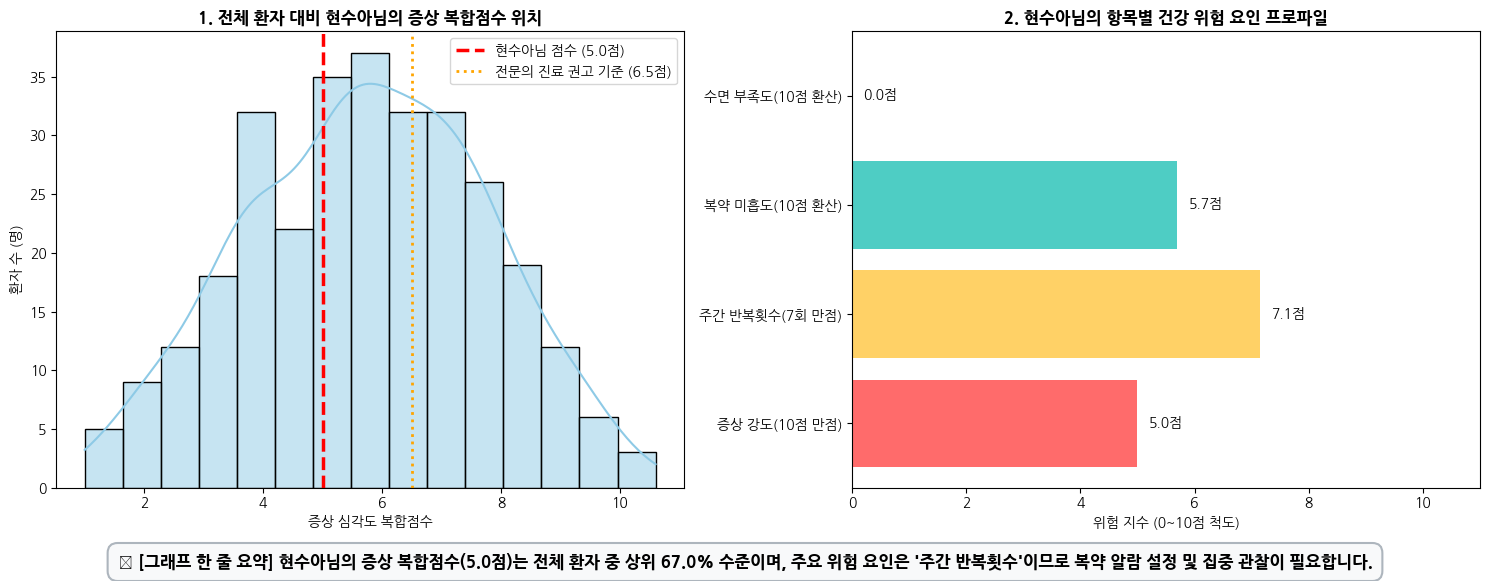

In [ ]:
!pip install -q koreanize-matplotlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import koreanize_matplotlib
from sklearn.tree import DecisionTreeClassifier

plt.rcParams['axes.unicode_minus'] = False

np.random.seed(42)
n_samples = 300

data = pd.DataFrame({
    '복용_약물_수': np.random.choice([2, 3, 5, 7, 10], size=n_samples, p=[0.25, 0.25, 0.25, 0.15, 0.10]),
    '복약_이행률(%)': np.random.uniform(45, 100, size=n_samples).round(1),
    '증상_강도': np.random.randint(1, 11, size=n_samples),
    '증상_지속일수': np.random.randint(1, 15, size=n_samples),
    '주간_반복횟수': np.random.randint(1, 8, size=n_samples),
    '수면_시간': np.random.uniform(3.5, 8.5, size=n_samples).round(1)
})

data['다약제_위험여부'] = np.where(data['복용_약물_수'] >= 5, 1, 0)
data['증상_복합점수'] = (data['증상_강도'] * 0.5 + data['증상_지속일수'] * 0.3 + data['주간_반복횟수'] * 0.2).round(2)
data['복약_미흡여부'] = np.where(data['복약_이행률(%)'] < 80.0, 1, 0)

def classify_health_status(row):
    if row['증상_복합점수'] >= 6.5 or (row['다약제_위험여부'] == 1 and row['증상_강도'] >= 7):
        return 2
    elif row['복약_미흡여부'] == 1 or row['주간_반복횟수'] >= 4:
        return 1
    else:
        return 0

data['건강변화_유형'] = data.apply(classify_health_status, axis=1)
label_names = ['안정 유지형', '복약 관리 필요형', '전문의 진료 권고형']

features = ['다약제_위험여부', '증상_복합점수', '복약_미흡여부', '주간_반복횟수', '수면_시간']
X = data[features]
y = data['건강변화_유형']

dt_model = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_model.fit(X, y)

print("=" * 55)
print("       [ONECARE AI] 일상 건강 및 복약 상태 입력")
print("=" * 55)

user_name = input("1. 성함을 입력하세요 (예: 박가을): ")
drug_cnt = int(input("2. 현재 복용 중인 처방약 개수를 입력하세요 (예: 5): "))
adherence = float(input("3. 최근 일주일 복약 이행률(%)을 입력하세요 (0~100, 예: 75): "))
symptom_name = input("4. 가장 불편한 증상을 입력하세요 (예: 어지러움, 속쓰림): ")
intensity = int(input("5. 증상 강도를 입력하세요 (1: 매우 약함 ~ 10: 매우 심함, 예: 7): "))
duration = int(input("6. 증상이 며칠째 지속되고 있나요? (예: 4): "))
frequency = int(input("7. 일주일 동안 해당 증상이 몇 번 반복되었나요? (예: 5): "))
sleep_hrs = float(input("8. 하루 평균 수면 시간을 입력하세요 (예: 5.5): "))

user_polypharmacy = 1 if drug_cnt >= 5 else 0
user_symptom_score = round(intensity * 0.5 + duration * 0.3 + frequency * 0.2, 2)
user_poor_adherence = 1 if adherence < 80.0 else 0

user_input_df = pd.DataFrame([{
    '다약제_위험여부': user_polypharmacy,
    '증상_복합점수': user_symptom_score,
    '복약_미흡여부': user_poor_adherence,
    '주간_반복횟수': frequency,
    '수면_시간': sleep_hrs
}])

pred_idx = dt_model.predict(user_input_df)[0]
pred_result = label_names[pred_idx]

print("\n" + "=" * 55)
print(f"       [ONECARE AI 진료 준비 자동 분석 보고서]")
print("=" * 55)
print(f"■ 환자 성함: {user_name} 님")
print(f"■ 주요 호소 증상: {symptom_name} (강도 {intensity}/10, {duration}일 지속, 주 {frequency}회)")
print(f"■ 가공된 핵심 건강 지표:")
print(f"  - 다약제 위험 여부: {'고위험군 (5개 이상 복용)' if user_polypharmacy == 1 else '일반군 (5개 미만 복용)'}")
print(f"  - 증상 심각도 복합점수: {user_symptom_score}점 (기준치: 6.5점 이상 고위험)")
print(f"  - 복약 순응도 평가: {'관리 미흡 (80% 미만)' if user_poor_adherence == 1 else '양호 (80% 이상)'}")
print("-" * 55)
print(f"▶ AI 종합 분류 결과: 【 {pred_result} 】")

if pred_idx == 2:
    print("▶ AI 권고 안내: 증상 복합점수가 높거나 다약제 복용 중 고강도 증상이 확인되었습니다.")
    print("   자체적인 약물 조절을 피하고, 본 보고서를 지참하여 빠른 시일 내에 전문의 진료를 권장합니다.")
elif pred_idx == 1:
    print("▶ AI 권고 안내: 복약 이행률이 낮거나 증상이 반복되고 있습니다.")
    print("   알람 설정을 통해 정해진 시간에 복약하시고, 3일 이상 증상 지속 시 병원 상담을 권장합니다.")
else:
    print("▶ AI 권고 안내: 현재 복약 및 건강 상태가 안정적으로 유지되고 있습니다.")
    print("   지금처럼 규칙적인 복약과 생활습관 기록을 이어가세요.")
print("=" * 55 + "\n")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.histplot(data['증상_복합점수'], bins=15, kde=True, color='#8ecae6', ax=axes[0])
axes[0].axvline(user_symptom_score, color='red', linestyle='--', linewidth=2.5, label=f'{user_name}님 점수 ({user_symptom_score}점)')
axes[0].axvline(6.5, color='orange', linestyle=':', linewidth=2, label='전문의 진료 권고 기준 (6.5점)')
axes[0].set_title(f'1. 전체 환자 대비 {user_name}님의 증상 복합점수 위치', fontsize=12, fontweight='bold')
axes[0].set_xlabel('증상 심각도 복합점수')
axes[0].set_ylabel('환자 수 (명)')
axes[0].legend()

user_metrics = ['증상 강도(10점 만점)', '주간 반복횟수(7회 만점)', '복약 미흡도(10점 환산)', '수면 부족도(10점 환산)']
user_values = [
    intensity,
    min(frequency, 7) * (10 / 7),
    round((100 - adherence) / 10, 1),
    max(0, round((8 - sleep_hrs) * 2, 1))
]

bars = axes[1].barh(user_metrics, user_values, color=['#ff6b6b', '#ffd166', '#4ecdc4', '#118ab2'])
axes[1].set_xlim(0, 11)
axes[1].set_title(f'2. {user_name}님의 항목별 건강 위험 요인 프로파일', fontsize=12, fontweight='bold')
axes[1].set_xlabel('위험 지수 (0~10점 척도)')
for bar, val in zip(bars, user_values):
    axes[1].text(val + 0.2, bar.get_y() + bar.get_height()/2, f'{val:.1f}점', va='center', fontsize=10)

percentile = (data['증상_복합점수'] < user_symptom_score).mean() * 100
max_factor = user_metrics[np.argmax(user_values)].split('(')[0]

if pred_idx == 2:
    action_msg = "전문의 진료 예약이 시급합니다."
elif pred_idx == 1:
    action_msg = "복약 알람 설정 및 집중 관찰이 필요합니다."
else:
    action_msg = "현재의 건강한 복약 습관을 유지해 주세요."

summary_text = f"📌 [그래프 한 줄 요약] {user_name}님의 증상 복합점수({user_symptom_score}점)는 전체 환자 중 상위 {100 - percentile:.1f}% 수준이며, 주요 위험 요인은 '{max_factor}'이므로 {action_msg}"

fig.text(0.5, -0.04, summary_text, ha='center', fontsize=12, fontweight='bold',
         bbox=dict(boxstyle='round,pad=0.6', facecolor='#f8f9fa', edgecolor='#adb5bd', linewidth=1.5))

plt.tight_layout()
plt.show()